# Corn store-or-sell: a walkthrough

## The question

On **October 15**, should a Central Illinois corn holder **store the corn until April 15**, hedged by selling
May corn futures, or **sell at harvest and put the cash in 6-month T-bills**? Storing pays only if the local
cash price gains enough on futures (the basis gain) to cover storage cost plus the T-bill interest given up.
This notebook follows the whole process, from raw data to an out-of-sample test, without opening any script.

*Every code cell only **reads** files that the numbered scripts already made; nothing here changes the data.
Full plan: [README](../README.md). Every decision: [processing log](../docs/processing_log.md).*

## Pipeline map

| Stage | Script | What it makes | Output file |
|---|---|---|---|
| **Raw** (evidence, never edited) | none: API pull, download or typed by hand | USDA bids, May futures, T-bill rates, storage costs | `data/raw/*.csv` |
| **Silver** (clean tables) | `03_build_silver.py` | current corn cash bids | `data/clean/corn_bids_current.csv` |
| | `04_clean_futures.py` | May futures in $/bu | `data/clean/may_futures.csv` |
| | `05_tbill_rates.py` | T-bill rate per decision date | `data/clean/tbill_decision.csv` |
| **Database** | `06_build_db.py` | one SQLite file with keys and checks | `data/clean/corn.db` |
| **Gold** (one row per year x region) | `07_build_gold.py` | gap, interest, storage cases, net gain | `data/gold/gold_yearly.csv` (+ table in `corn.db`) |
| **Charts** | `08_charts.py` | scatter and bar chart | `outputs/scatter_gap.png`, `outputs/bars_by_year.png` |
| **Walk-forward scoreboard** | `09_walk_forward.py` | out-of-sample test of 4 strategies | `outputs/walk_forward_predictions.csv`, `outputs/scoreboard.csv` |

```
raw  ->  silver (03, 04, 05)  ->  database (06)  ->  gold (07)  ->  charts (08)
                                                          \->  walk-forward scoreboard (09)
```

There is no separate "bronze" layer: the raw files are kept exactly as received, and the silver scripts read them directly.

## Setup

In [1]:
# Find the project folder, so the notebook runs from anywhere. Nothing below writes files.
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path.cwd()
while not (ROOT / "notebooks/09_walk_forward.py").exists():
    ROOT = ROOT.parent
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

## Step 0: Raw data (no script in this repository)

**Why this step:** Every later number must trace back to an untouched source file.

**Input:** USDA MyMarketNews report 3192 (12 Oct/Apr monthly pulls), `may_futures.csv` (typed from Barchart), `fred_dtb6.csv` (FRED download), `storage_costs.csv` (typed from articles).

**What the script does:**
- Cash bids were pulled from the USDA MyMarketNews API one month at a time (the API caps each request at 100,000 records).
- The 12 May futures settlements (Oct 15 and Apr 15, 6 contracts) were typed by hand from Barchart in cents-and-eighths, e.g. `409-2`.
- The 6-month T-bill series DTB6 was downloaded from FRED; storage costs were typed from two articles, with the source URL on every row.

**Output preview:**

In [2]:
# Count rows in each raw file the pipeline uses (the leftover test pull is skipped)
files = sorted(f for f in (ROOT / "data/raw").glob("*.csv") if not f.name.startswith("test_"))
raw = pd.DataFrame({"file": [f.name for f in files],
                    "rows": [len(pd.read_csv(f, low_memory=False)) for f in files]})
print(f"{len(raw)} raw files")
display(raw)

15 raw files


,file,rows
0,3192_2020-10.csv,1008
1,3192_2021-04.csv,1029
2,3192_2021-10.csv,976
3,3192_2022-04.csv,994
4,3192_2022-10.csv,985
5,3192_2023-04.csv,949
6,3192_2023-10.csv,1101
7,3192_2024-04.csv,1102
8,3192_2024-10.csv,1115
9,3192_2025-04.csv,1050


**Takeaway:** the evidence is 12 USDA files (12,486 rows), 12 futures settlements, 17,707 daily T-bill rates and 6 storage-cost rows; raw files are never edited (the one approved exception was typing in the 12 futures prices).

*Details:* [processing log: Raw vs Clean](../docs/processing_log.md#raw-vs-clean)

## Step 03: Silver cash bids

**Why this step:** We need one clean cash price per region, buyer and day for corn that can be delivered now.

**Input:** `data/raw/3192_YYYY-MM.csv` (the 12 Oct/Apr files, listed by name).

**What the script does:**
- Stacks the 12 files and keeps 13 useful columns.
- Keeps corn bids for current delivery only; all regions and buyer types stay.
- Renames columns to plain names and converts dates to YYYY-MM-DD.
- Drops 8 empty duplicate rows (no price, same key as a real row).

**Output preview:**

In [3]:
# The silver table: current corn cash bids, in $/bushel
silver = pd.read_csv(ROOT / "data/clean/corn_bids_current.csv")
print("shape:", silver.shape)
display(silver[["date", "region", "buyer_type", "cash_price", "cash_price_low", "cash_price_high"]].head())

shape: (3024, 13)


,date,region,buyer_type,cash_price,cash_price_low,cash_price_high
0,2020-10-01,Central,Mills and Processors,3.7192,3.5475,3.7975
1,2020-10-01,Chicago,Mills and Processors,3.8875,3.8175,3.9575
2,2020-10-01,Chicago,Terminal Elevators,3.5275,3.3775,3.6775
3,2020-10-01,Little Egypt,Country Elevators,3.7895,3.6675,3.9475
4,2020-10-01,North,Country Elevators,3.5755,3.4775,3.6275


**Takeaway:** only 3,024 of 12,486 raw rows are current corn bids; the 8 empty duplicates were the only rows dropped for quality, and no prices are missing.

*Details:* [processing log: 03_build_silver.py: cash bids (silver table)](../docs/processing_log.md#03_build_silverpy-cash-bids-silver-table)

## Step 04: May futures in $/bushel

**Why this step:** The hedge uses the May contract on both dates, so its price must be exact.

**Input:** `data/raw/may_futures.csv` (12 rows: 6 decision years x Oct/Apr).

**What the script does:**
- Converts cents-and-eighths to $/bu: `409-2` = 409.25 cents = $4.0925.
- Labels each row as the Oct leg (open the hedge) or the Apr leg (close it).
- Stops if a quote is not in the `583-2` format; blank cells would stay blank.

**Output preview:**

In [4]:
# Raw quote next to the converted price
fut = pd.read_csv(ROOT / "data/clean/may_futures.csv")
print("shape:", fut.shape)
display(fut[["decision_year", "date", "futures_contract", "leg", "settle_raw", "may_futures_price"]].head())

shape: (12, 8)


,decision_year,date,futures_contract,leg,settle_raw,may_futures_price
0,2020,2020-10-15,ZCK21,Oct (open hedge),409-2,4.0925
1,2020,2021-04-15,ZCK21,Apr (close hedge),590-0,5.9000
2,2021,2021-10-15,ZCK22,Oct (open hedge),538-6,5.3875
3,2021,2022-04-14,ZCK22,Apr (close hedge),790-2,7.9025
4,2022,2022-10-14,ZCK23,Oct (open hedge),697-2,6.9725


**Takeaway:** all 12 prices are present ($4.09 to $7.90); reading `409-2` as 409.2 cents would have been wrong.

*Details:* [processing log: 2026-11-08: May futures prices entered in raw file (one-time raw edit, approved by user)](../docs/processing_log.md#2026-11-08-may-futures-prices-entered-in-raw-file-one-time-raw-edit-approved-by-user)

## Step 05: T-bill rate for the interest cost

**Why this step:** Storing ties up cash that could earn the T-bill rate, so that interest is part of the hurdle.

**Input:** `data/raw/fred_dtb6.csv` (daily, in percent).

**What the script does:**
- Drops blank rows (bond-market holidays); nothing is filled.
- Averages the rate over the 10 calendar days ending on each decision date, never using a later date.
- Converts percent to a decimal (4.02% -> 0.0402).

**Output preview:**

In [5]:
# One rate per decision date
tbill = pd.read_csv(ROOT / "data/clean/tbill_decision.csv")
print("shape:", tbill.shape)
display(tbill[["decision_year", "decision_date", "n_days_used", "dtb6_avg_pct", "rate_decimal"]].head())

shape: (6, 7)


,decision_year,decision_date,n_days_used,dtb6_avg_pct,rate_decimal
0,2020,2020-10-15,7,0.12%,0.001186
1,2021,2021-10-15,7,0.06%,0.000614
2,2022,2022-10-14,7,4.02%,0.040229
3,2023,2023-10-13,7,5.33%,0.053343
4,2024,2024-10-15,6,4.30%,0.042983


**Takeaway:** the rate went from about 0.1% (2020-2021) to 3.7-5.3% (2022-2025), so interest moved from negligible to a real part of the hurdle; 2024 used 6 days because FRED is blank on 2024-10-14.

*Details:* [processing log: 05_tbill_rates.py: T-bill rate for the hurdle](../docs/processing_log.md#05_tbill_ratespy-t-bill-rate-for-the-hurdle)

## Step 06: SQLite database

**Why this step:** One database with keys lets the gold step join prices safely by date.

**Input:** the three silver CSVs.

**What the script does:**
- Builds `corn.db` with 4 tables: `calendar`, `corn_bids`, `may_futures`, `tbill_decision`.
- Checks for duplicate keys, blank keys and dates missing from the calendar before loading.
- Rebuilds from scratch, so step 07 must always run after it.

**Output preview:**

In [6]:
# Tables and row counts, opened read-only
con = sqlite3.connect(f"file:{ROOT / 'data/clean/corn.db'}?mode=ro", uri=True)
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", con)
tables["rows"] = [con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in tables["name"]]
con.close()
display(tables)

,name,rows
0,calendar,2557
1,corn_bids,3024
2,gold_yearly,12
3,may_futures,12
4,tbill_decision,6


**Takeaway:** all keys and foreign keys pass; the database also holds the gold table written by step 07.

*Details:* [processing log: 06_build_db.py: SQLite database](../docs/processing_log.md#06_build_dbpy-sqlite-database)

## Step 07: Gold table

**Why this step:** The decision needs one row per year and region with every number the rule uses.

**Input:** `data/clean/corn.db` and `data/raw/storage_costs.csv`.

**What the script does:**
- Picks North Central and South Central country elevators, decision years 2020-2025.
- Gap (cents) = May futures - cash; gap closed = Oct gap - Apr gap: what the hedged storage earns.
- Interest = T-bill rate x 0.5 year x Oct cash price.
- For each storage case: hurdle = storage + interest, and net gain = gap closed - hurdle.

**Output preview:**

In [7]:
# The key columns of the gold table, in cents per bushel
gold = pd.read_csv(ROOT / "data/gold/gold_yearly.csv")
print("shape:", gold.shape)
display(gold[["decision_year", "region", "gap_oct_cents", "gap_apr_cents", "gap_closed_cents",
              "interest_cents", "breakeven_storage_cents"]].head())

shape: (12, 27)


,decision_year,region,gap_oct_cents,gap_apr_cents,gap_closed_cents,interest_cents,breakeven_storage_cents
0,2020,North Central,29.80,7.89,21.91,0.224960,21.685040
1,2020,South Central,29.38,-0.19,29.57,0.225209,29.344791
2,2021,North Central,40.56,20.56,20.00,0.153015,19.846985
3,2021,South Central,32.12,9.62,22.50,0.155608,22.344392
4,2022,North Central,35.75,7.69,28.06,13.305600,14.754400


**Takeaway:** the gap closed by 20 to 43 cents every year, more than interest alone, so the answer depends on what storage costs (break-even storage cost: 15 to 36 cents).

*Details:* [processing log: 2026-11-13: storage cost cases added to gold (06 → 07 → 08 rerun)](../docs/processing_log.md#2026-11-13-storage-cost-cases-added-to-gold-06--07--08-rerun)

## Step 08: Charts

**Why this step:** A picture shows whether a wide October gap predicts a large gain, and which hurdles each year clears.

**Input:** `data/gold/gold_yearly.csv`.

**What the script does:**
- Scatter: October gap vs. gap closed, one color per region, with fitted lines.
- Bars: gap closed per year against the low, mid and high hurdles, one panel per region.

**Output preview:**

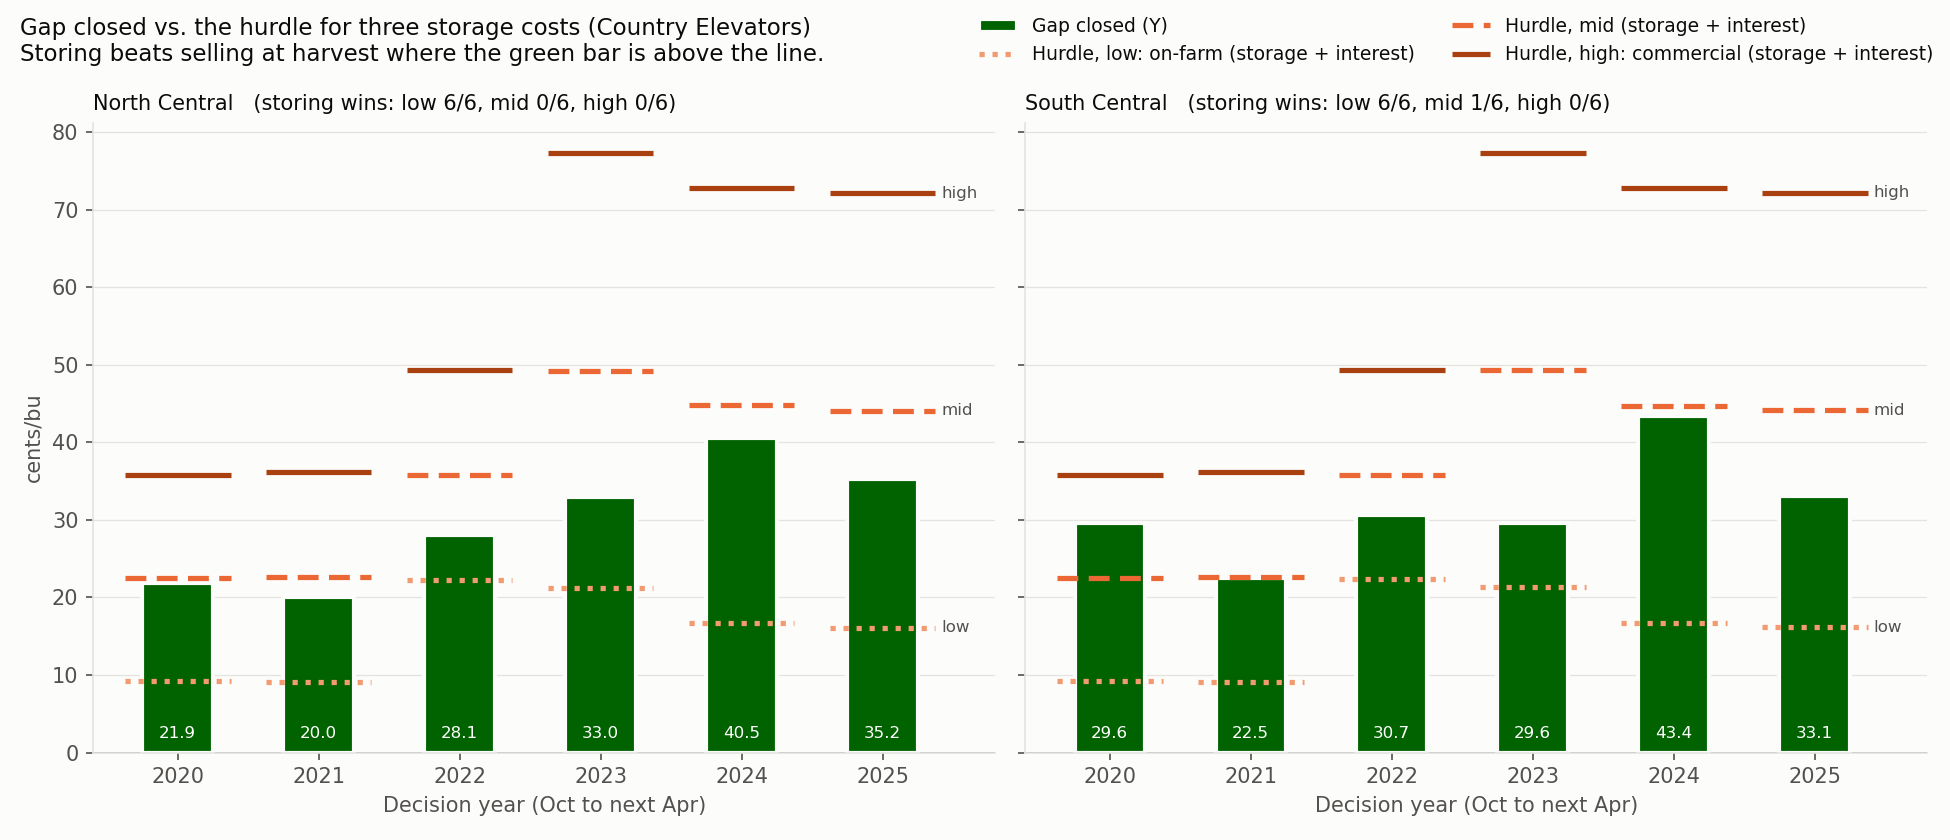

In [8]:
# Show the bar chart saved by 08_charts.py (gap closed vs. the three hurdles)
display(Image(filename=str(ROOT / "outputs/bars_by_year.png"), width=750))

**Takeaway:** a wider October gap tends to close more (pooled slope 0.41, R-squared 0.67, n = 12); the low hurdle is cleared every year, the high hurdle never.

*Details:* [processing log: 2026-11-13: breakeven column, new bar chart, README storage item resolved](../docs/processing_log.md#2026-11-13-breakeven-column-new-bar-chart-readme-storage-item-resolved)

## Step 09: Walk-forward test

**Why this step:** A rule is only useful if it works on years it has not seen.

**Input:** `data/gold/gold_yearly.csv`.

**What the script does:**
- Predicts each test year (2023, 2024, 2025) using only earlier years: 3 rounds, 6/8/10 training rows.
- Two forecasts of gap closed: past average, and a regression on the October gap.
- Rule: store if forecast - interest > storage cost; scores 4 strategies under each storage case.

**Output preview:**

In [9]:
# One row per test year x region: forecast vs. actual
pred = pd.read_csv(ROOT / "outputs/walk_forward_predictions.csv")
print("shape:", pred.shape)
display(pred[["test_year", "region", "train_years", "slope", "actual_gap_closed_cents",
              "pred_regression_cents", "pred_past_average_cents"]].head())

shape: (6, 32)


,test_year,region,train_years,slope,actual_gap_closed_cents,pred_regression_cents,pred_past_average_cents
0,2023,North Central,2020-2022,-0.264058,33.00,19.292947,25.451667
1,2023,South Central,2020-2022,-0.264058,29.56,20.182823,25.451667
2,2024,North Central,2020-2023,0.214699,40.50,32.607667,26.908750
3,2024,South Central,2020-2023,0.214699,43.37,32.794455,26.908750
4,2025,North Central,2020-2024,0.418379,35.25,35.624037,29.914000


**Takeaway:** round 1 had only 6 training rows and fitted a negative slope (-0.26), which made the regression forecast 2023 too low.

*Details:* [processing log: 2026-11-13: 09 walk-forward test (first out-of-sample results)](../docs/processing_log.md#2026-11-13-09-walk-forward-test-first-out-of-sample-results)

## Key decisions

> **Storage cost: three cases for the 6-month hold (cents per bushel)**
> - **Low, 9 cents every year:** on-farm bins, 1.5 cents/month x 6 (Iowa Farm Bureau, 2016; a weaker source).
> - **High, 35.5 to 65 cents:** commercial physical storage from farmdoc daily (Zulauf, Paulson & Janzen, Oct 2025),
>   annual cost x 0.5. Read from the article's chart; the 2025 value repeats 2024 (flagged). From one Ohio elevator, and
>   halving probably understates a 6-month commercial charge.
> - **Mid:** the average of low and high.
>
> **Hedge timing:** open on Oct 15 (sell May futures), close on Apr 15 (sell the corn, buy back the futures).
> Closing in mid-April exits before the May contract's delivery period. *(First notice day for May corn is at the
> end of April: still to be confirmed against CME's contract rules.)*
>
> **Dates and futures gaps:** no futures prices were filled or estimated. All 12 settlements were typed from Barchart,
> and any value that had been missing would have stayed blank. When Oct 15 or Apr 15 was not a trading day, the
> nearest *prior* trading day is used (table below).
>
> *Details:* [processing log: 2026-11-13: storage cost cases added to gold (06 → 07 → 08 rerun)](../docs/processing_log.md#2026-11-13-storage-cost-cases-added-to-gold-06--07--08-rerun)

In [10]:
# Decision dates that were not the 15th (market closed on the 15th)
dates = fut[["decision_year", "leg", "date"]]
display(dates[~dates["date"].str.endswith("-15")])
display(pd.read_csv(ROOT / "data/raw/storage_costs.csv").iloc[:, :4])

,decision_year,leg,date
3,2021,Apr (close hedge),2022-04-14
4,2022,Oct (open hedge),2022-10-14
5,2022,Apr (close hedge),2023-04-14
6,2023,Oct (open hedge),2023-10-13


,decision_year,storage_low_cents,storage_mid_cents,storage_high_cents
0,2020,9.0,22.25,35.5
1,2021,9.0,22.50,36.0
2,2022,9.0,22.50,36.0
3,2023,9.0,37.00,65.0
4,2024,9.0,37.00,65.0
5,2025,9.0,37.00,65.0


## Results

### Gold table: did storing beat selling? (net gain, cents/bu; positive = store wins)

In [11]:
# Average net gain over the 2 regions, and how many of the 2 regions stored profitably
cases = ["low", "mid", "high"]
net = gold.groupby("decision_year")[[f"net_gain_{c}_cents" for c in cases]].mean().round(1)
wins = gold.groupby("decision_year")[[f"store_wins_{c}" for c in cases]].sum()
net.columns = [f"{c}: net gain" for c in cases]; wins.columns = [f"{c}: wins of 2" for c in cases]
display(pd.concat([net, wins], axis=1))

,low: net gain,mid: net gain,high: net gain,low: wins of 2,mid: wins of 2,high: wins of 2
decision_year,,,,,,
2020,16.5,3.3,-10.0,2,1,0
2021,12.1,-1.4,-14.9,2,0,0
2022,7.1,-6.4,-19.9,2,0,0
2023,10.0,-18.0,-46.0,2,0,0
2024,25.2,-2.8,-30.8,2,0,0
2025,18.1,-9.9,-37.9,2,0,0


**Takeaway:** at the low (on-farm) cost, storing won in all 12 region-years; at mid cost, in 1 of 12 (2020 South Central); at high cost, never.

### Walk-forward scoreboard (3 test years x 2 regions = 6 rows)

In [12]:
# Total net gain (cents/bu over 6 rows) and correct calls (of 6), by strategy and storage case
score = pd.read_csv(ROOT / "outputs/scoreboard.csv")
display(score.pivot(index="strategy", columns="storage_case", values="total_net_gain_cents").round(1)[cases])
display(score.pivot(index="strategy", columns="storage_case", values="correct_calls")[cases])
mae = pred[["err_regression_cents", "err_past_average_cents"]].abs().mean().round(2)
print("Forecast error (MAE, cents/bu):", mae.to_dict())

storage_case,low,mid,high
strategy,,,
always sell,0.0,0.0,0.0
always store,106.5,-61.5,-229.5
past average,106.5,0.0,0.0
regression,86.5,0.0,0.0


storage_case,low,mid,high
strategy,,,
always sell,0,6,6
always store,6,0,0
past average,6,6,6
regression,4,6,6


Forecast error (MAE, cents/bu): {'err_regression_cents': 7.16, 'err_past_average_cents': 8.38}


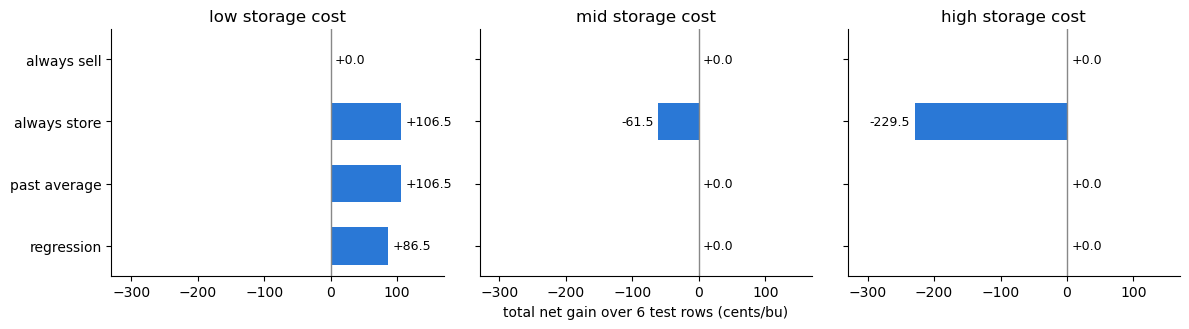

In [13]:
# One chart: total net gain by strategy, one panel per storage case (0 = always sell)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, c in zip(axes, cases):
    s = score[score["storage_case"] == c].set_index("strategy")["total_net_gain_cents"]
    ax.barh(s.index, s.values, color="#2a78d6", height=0.6); ax.axvline(0, color="#888", lw=1)
    ax.bar_label(ax.containers[0], fmt="%+.1f", padding=3, fontsize=9); ax.set_title(f"{c} storage cost")
    ax.set_xlim(-330, 170); ax.spines[["top", "right"]].set_visible(False)
axes[0].invert_yaxis()  # list strategies top-down in table order
axes[1].set_xlabel("total net gain over 6 test rows (cents/bu)"); plt.tight_layout(); plt.show()

**Takeaway:** the regression had the smaller forecast error (MAE 7.16 vs. 8.38 cents) but made worse low-cost decisions (4 of 6 correct vs. 6 of 6), so a more accurate forecast did not mean better decisions. *Details:* [processing log: 2026-11-13: 09 walk-forward test (first out-of-sample results)](../docs/processing_log.md#2026-11-13-09-walk-forward-test-first-out-of-sample-results)

## What this means

- **Storage cost decides the answer.** With on-farm storage (about 9 cents), hedged storage paid every year;
  at commercial rates, selling at harvest and buying T-bills was almost always better.
- **A simple rule was enough here.** "Store if the past average gain beats the hurdle" made every right call in
  the test; the regression made two wrong calls.
- **Accuracy is not the goal; decisions are.** Only errors near the hurdle change the decision, which is why
  the model with the lower error still lost money against the simple rule.

## Limits and next steps

- **Very little data:** 6 decision years; round 1 of the test trained on only 6 rows, and there are only 3 test
  years. These results are practice, not a conclusion.
- **Storage cost is the weakest input:** the low case is one 2016 range; the high case is an Ohio elevator's annual
  cost, halved. Commissions, margin interest and grain shrink are not counted.
- **Next:** an Apr-vs-Oct basis check, the Phase 2 backfill to about 20 years, and migrating the pipeline to
  Databricks.